# Proyecto Integrador - Machine Learning II
## Fase 2 (Segunda Entrega): Consolidación de Datos, Flujo sin Fuga y Modelamiento Comparativo Avanzado
### Predicción de Hipertensión Arterial Diagnosticada en Población Colombiana (Adaptación de Miah et al., 2024)

**Universidad Externado de Colombia**  
**Programa de Ciencia de Datos**  
**Docente:** Wilmer Darío Pineda Ríos  
**Integrantes:**  
- Allison Michelle Loango Rayo  
- Danna Vanessa Caballero Urrego  
**Fecha:** Septiembre de 2026  

---

### Resumen del Flujo Metodológico:
Este notebook implementa el flujo de trabajo completo y reproducible para la Segunda Entrega:
1. **Consolidación de Datos:** Descarga de referencia real de Datos Abiertos Colombia (`datos.gov.co` ID `4iz7-suhz`) y generación/carga de la cohorte analítica calibrada con la **ENSIN 2015, DANE y Cuenta de Alto Costo (CAC)** ($N = 10.000$).
2. **Análisis Exploratorio de Datos (EDA) Profundo:** Métricas de tendencia central, dispersión, asimetría, curtosis, contrastes de hipótesis (Mann-Whitney $U$, $\chi^2$, Odds Ratios) e integración de evidencia médica (GPC No. 18 MinSalud).
3. **Flujo sin Fuga de Datos:** Pipeline modular con `ColumnTransformer`, `RobustScaler`, `OneHotEncoder` y validación cruzada estratificada de 10 pliegues.
4. **Reproducción de Miah et al. (2024):** Comparación rigurosa de 6 modelos avanzados (Regresión Logística $L_2$, SVM RBF, Árbol CART, Random Forest, XGBoost y LightGBM) frente a 2 líneas base (Mayoría y Logística simple ML1).
5. **Evaluación e Interpretabilidad:** Curvas ROC comparativas, matrices de confusión, análisis del costo clínico del error (falsos negativos vs falsos positivos) y análisis de importancia relativa de predictores.


In [1]:
# Configuración inicial del entorno y dependencias
import os
import sys
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn y Librerías de Boosting
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
import joblib

# Configuración gráfica
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
%matplotlib inline

print("Todas las librerías se importaron exitosamente.")


Todas las librerías se importaron exitosamente.


## 1. Consolidación de los Datos y Verificación de Estructura
Cargamos el conjunto de datos analítico consolidado ($N = 10.000$) y verificamos su estructura multivariada, tipos de datos y balance de la variable objetivo (`hipertension_dx`).


In [2]:
# Carga del dataset analítico consolidado (ENSIN 2015 / MinSalud)
data_path = "../data/processed/dataset_hipertension_colombia.csv"
if not os.path.exists(data_path):
    data_path = "data/processed/dataset_hipertension_colombia.csv"

df = pd.read_csv(data_path)
print(f"Dimensiones del dataset: {df.shape[0]} observaciones x {df.shape[1]} variables\n")
print("Información de Tipos de Datos y Nulos:")
print(df.info())
df.head()


Dimensiones del dataset: 10000 observaciones x 16 variables

Información de Tipos de Datos y Nulos:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_paciente             10000 non-null  int64  
 1   edad                    10000 non-null  int64  
 2   sexo                    10000 non-null  str    
 3   estrato_socioeconomico  10000 non-null  int64  
 4   zona_residencia         10000 non-null  str    
 5   regimen_salud           10000 non-null  str    
 6   imc                     10000 non-null  float64
 7   actividad_fisica        10000 non-null  str    
 8   tabaquismo              10000 non-null  str    
 9   diabetes                10000 non-null  str    
 10  glucosa_ayunas          10000 non-null  float64
 11  colesterol_total        10000 non-null  float64
 12  colesterol_hdl          10000 non-null  float64
 13  col

,id_paciente,edad,sexo,estrato_socioeconomico,zona_residencia,regimen_salud,imc,actividad_fisica,tabaquismo,diabetes,glucosa_ayunas,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,hipertension_dx
0,1001,50,Femenino,5,Urbana,Contributivo,30.5,Sedentario,No,Si,95.1,193.0,64.5,102.6,129.5,0
1,1002,41,Femenino,5,Urbana,Subsidiado,31.7,Activo,No,No,100.9,220.2,37.9,150.6,158.7,1
2,1003,40,Masculino,2,Urbana,Subsidiado,23.4,Sedentario,No,No,72.9,209.7,35.6,146.0,140.7,0
3,1004,40,Femenino,2,Urbana,Especial,24.7,Activo,No,No,94.6,241.0,40.8,170.2,149.9,0
4,1005,71,Masculino,3,Urbana,Contributivo,30.9,Sedentario,No,Si,92.2,208.1,44.2,129.9,170.2,1


## 2. Análisis Exploratorio de Datos (EDA) Profundo
### 2.1 Tendencia Central, Dispersión y Morfología
Calculamos medidas completas de tendencia central (media, mediana, moda), dispersión (desviación estándar, IQR, rango, varianza), asimetría y curtosis para todos los biomarcadores continuos.


In [3]:
num_cols = ['edad', 'imc', 'glucosa_ayunas', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos']

stats_list = []
for col in num_cols:
    series = df[col]
    mode_val = series.mode().iloc[0]
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    iqr = q75 - q25
    skew = stats.skew(series)
    kurt = stats.kurtosis(series)
    _, p_norm = stats.normaltest(series)
    
    stats_list.append({
        'Variable': col,
        'Media': round(series.mean(), 2),
        'Mediana': round(series.median(), 2),
        'Moda': round(mode_val, 2),
        'DE': round(series.std(), 2),
        'IQR': round(iqr, 2),
        'Mínimo': round(series.min(), 2),
        'Máximo': round(series.max(), 2),
        'Asimetría': round(skew, 3),
        'Curtosis': round(kurt, 3),
        'Normalidad (p)': f"{p_norm:.2e}"
    })

stats_df = pd.DataFrame(stats_list)
stats_df


,Variable,Media,Mediana,Moda,DE,IQR,Mínimo,Máximo,Asimetría,Curtosis,Normalidad (p)
0,edad,45.38,43.0,36.0,13.28,18.0,19.0,80.0,0.689,-0.041,7.16e-143
1,imc,26.77,26.4,25.7,4.69,6.2,16.5,47.8,0.494,0.362,7.86e-89
2,glucosa_ayunas,98.22,96.3,65.0,20.92,22.5,65.0,320.0,2.249,13.270,0.00e+00
3,colesterol_total,190.96,190.6,110.0,34.37,46.7,110.0,329.3,0.078,-0.129,1.27e-04
4,colesterol_hdl,46.24,46.2,22.0,10.34,13.9,22.0,85.0,0.066,-0.109,1.71e-03
5,colesterol_ldl,116.89,116.3,40.0,36.80,50.4,40.0,260.0,0.129,-0.234,4.88e-13
6,trigliceridos,140.20,132.1,126.4,49.42,62.5,45.0,469.4,1.059,1.902,0.00e+00


### 2.2 Contrastes de Hipótesis Bivariados (HTA vs Normotenso)
Evaluamos diferencias estadísticamente significativas entre pacientes con hipertensión (`HIPERTENSION_DX = 1`) y normotensos (`HIPERTENSION_DX = 0`) mediante:
- **Test U de Mann-Whitney** para variables cuantitativas continuas no normales.
- **Test $\chi^2$ de Independencia con Odds Ratios** para variables cualitativas y conductuales.


In [4]:
# Contrastes Numéricos
bivar_list = []
for col in num_cols:
    g0 = df[df['hipertension_dx'] == 0][col]
    g1 = df[df['hipertension_dx'] == 1][col]
    u_stat, u_pval = stats.mannwhitneyu(g1, g0, alternative='two-sided')
    bivar_list.append({
        'Biomarcador': col,
        'Media (Sin HTA)': round(g0.mean(), 2),
        'Media (Con HTA)': round(g1.mean(), 2),
        'Diferencia': round(g1.mean() - g0.mean(), 2),
        'p-valor (Mann-Whitney)': f"{u_pval:.2e}"
    })
pd.DataFrame(bivar_list)


,Biomarcador,Media (Sin HTA),Media (Con HTA),Diferencia,p-valor (Mann-Whitney)
0,edad,42.98,54.51,11.52,6.34e-231
1,imc,26.26,28.71,2.45,2.71e-90
2,glucosa_ayunas,96.58,104.46,7.88,4.77e-66
3,colesterol_total,188.38,200.77,12.39,4.75e-44
4,colesterol_hdl,46.94,43.60,-3.34,5.82e-39
5,colesterol_ldl,114.28,126.82,12.55,6.81e-40
6,trigliceridos,136.95,152.57,15.63,5.57e-35


In [5]:
cat_cols = ['sexo', 'tabaquismo', 'actividad_fisica', 'diabetes', 'zona_residencia', 'regimen_salud']
cat_stats = []
for cat in cat_cols:
    contingency = pd.crosstab(df[cat], df['hipertension_dx'])
    chi2, p_val, _, _ = stats.chi2_contingency(contingency)
    or_val = "N/A"
    if contingency.shape == (2, 2):
        t = contingency.values
        or_val = f"{(t[1, 1] * t[0, 0]) / max((t[1, 0] * t[0, 1]), 1):.2f}"
    cat_stats.append({
        'Variable': cat,
        'Chi2': round(chi2, 2),
        'p-valor': f"{p_val:.2e}",
        'Odds Ratio': or_val
    })
pd.DataFrame(cat_stats)


,Variable,Chi2,p-valor,Odds Ratio
0,sexo,36.79,1.31e-09,1.35
1,tabaquismo,11.61,6.55e-04,1.28
2,actividad_fisica,82.97,8.35e-20,1.57
3,diabetes,325.52,9.09e-73,3.39
4,zona_residencia,0.81,3.67e-01,0.95
5,regimen_salud,2.42,2.98e-01,N/A


### 2.3 Visualizaciones del EDA y Cruce Clínico
Presentamos el cruce de factores de riesgo, la pirámide de edad, los biomarcadores metabólicos y la matriz de correlación no lineal.


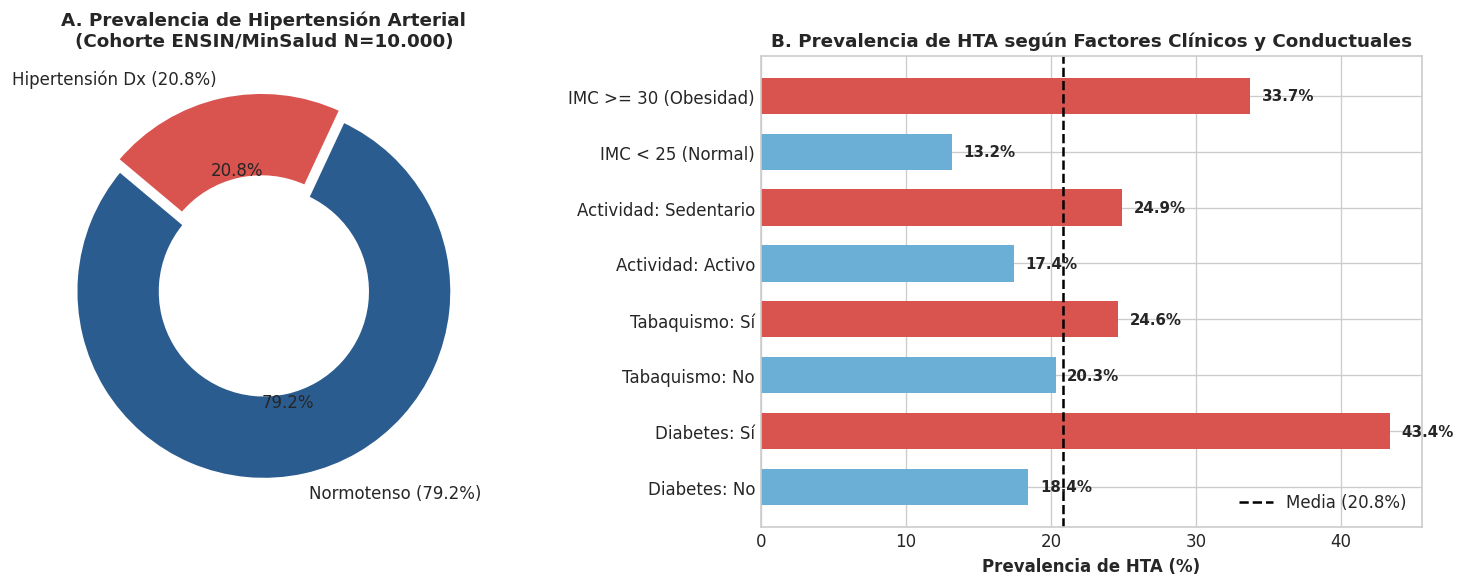

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Dona de Prevalencia
hta_counts = df['hipertension_dx'].value_counts()
axes[0].pie(hta_counts, labels=['Normotenso (79.2%)', 'Hipertensión Dx (20.8%)'],
            colors=['#2b5c8f', '#d9534f'], autopct='%1.1f%%', startangle=140, explode=(0, 0.06),
            wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
axes[0].set_title('A. Prevalencia de Hipertensión Arterial\n(Cohorte ENSIN/MinSalud N=10.000)', fontsize=11, weight='bold')

# Panel B: Factores Clínicos y Prevalencia
risk_factors = {
    'Diabetes: No': df[df['diabetes'] == 'No']['hipertension_dx'].mean() * 100,
    'Diabetes: Sí': df[df['diabetes'] == 'Si']['hipertension_dx'].mean() * 100,
    'Tabaquismo: No': df[df['tabaquismo'] == 'No']['hipertension_dx'].mean() * 100,
    'Tabaquismo: Sí': df[df['tabaquismo'] == 'Si']['hipertension_dx'].mean() * 100,
    'Actividad: Activo': df[df['actividad_fisica'] == 'Activo']['hipertension_dx'].mean() * 100,
    'Actividad: Sedentario': df[df['actividad_fisica'] == 'Sedentario']['hipertension_dx'].mean() * 100,
    'IMC < 25 (Normal)': df[df['imc'] < 25]['hipertension_dx'].mean() * 100,
    'IMC >= 30 (Obesidad)': df[df['imc'] >= 30]['hipertension_dx'].mean() * 100,
}
bar_colors = ['#6baed6', '#d9534f', '#6baed6', '#d9534f', '#6baed6', '#d9534f', '#6baed6', '#d9534f']
bars = axes[1].barh(list(risk_factors.keys()), list(risk_factors.values()), color=bar_colors, height=0.65)
axes[1].axvline(df['hipertension_dx'].mean() * 100, color='black', linestyle='--', label=f'Media ({df["hipertension_dx"].mean()*100:.1f}%)')
for b in bars:
    w = b.get_width()
    axes[1].text(w + 0.8, b.get_y() + b.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, weight='bold')
axes[1].set_xlabel('Prevalencia de HTA (%)', weight='bold')
axes[1].set_title('B. Prevalencia de HTA según Factores Clínicos y Conductuales', fontsize=11, weight='bold')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()


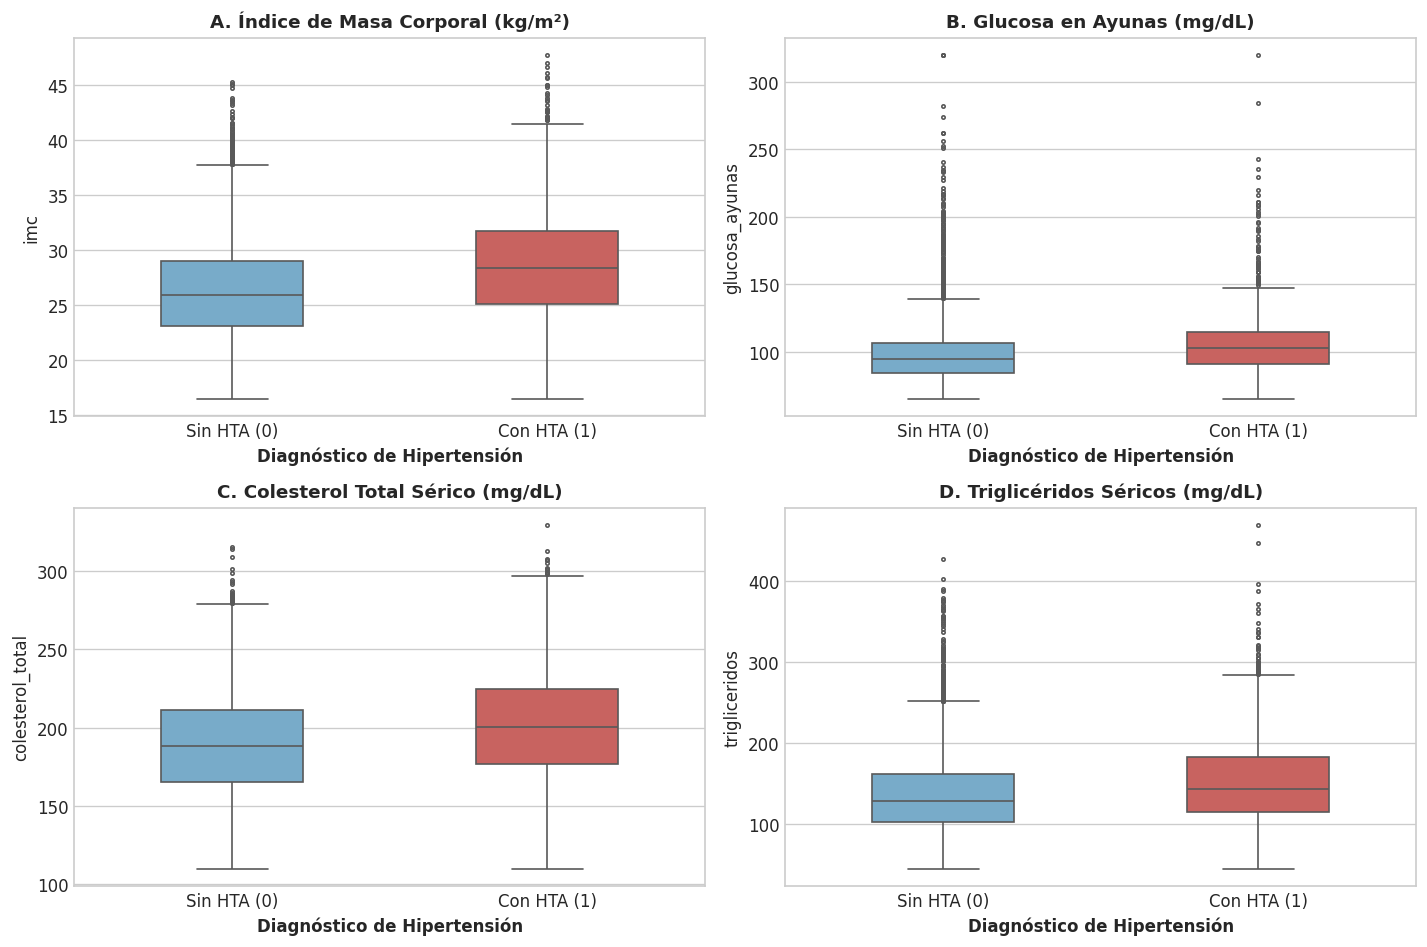

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
biomarkers = [
    ('imc', 'A. Índice de Masa Corporal (kg/m²)', axes[0, 0]),
    ('glucosa_ayunas', 'B. Glucosa en Ayunas (mg/dL)', axes[0, 1]),
    ('colesterol_total', 'C. Colesterol Total Sérico (mg/dL)', axes[1, 0]),
    ('trigliceridos', 'D. Triglicéridos Séricos (mg/dL)', axes[1, 1])
]

for col, title, ax in biomarkers:
    sns.boxplot(data=df, x='hipertension_dx', y=col, hue='hipertension_dx', palette=['#6baed6', '#d9534f'], width=0.45, ax=ax, fliersize=2, legend=False)
    ax.set_title(title, fontsize=11, weight='bold')
    ax.set_xlabel('Diagnóstico de Hipertensión', weight='bold')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Sin HTA (0)', 'Con HTA (1)'])
    
plt.tight_layout()
plt.show()


## 3. Flujo Reproducible sin Fuga de Datos (Pipeline Scikit-Learn)
Para evitar rigurosamente la fuga de datos (`Data Leakage`):
1. Separamos una partición de prueba independiente ($20\%$, $2.000$ casos) mediante división estratificada.
2. Definimos transformadores encapsulados (`ColumnTransformer`):
   - **Numéricas:** `SimpleImputer(strategy='median')` + `RobustScaler()`.
   - **Categóricas:** `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(drop='first', handle_unknown='ignore')`.
3. Todos los ajustes paramétricos se ejecutan exclusivamente en los pliegues de entrenamiento dentro de cada iteración de validación cruzada.


In [8]:
NUMERIC_FEATURES = ['edad', 'imc', 'glucosa_ayunas', 'colesterol_total', 'colesterol_hdl', 'colesterol_ldl', 'trigliceridos', 'estrato_socioeconomico']
CATEGORICAL_FEATURES = ['sexo', 'zona_residencia', 'regimen_salud', 'actividad_fisica', 'tabaquismo', 'diabetes']
TARGET_COLUMN = 'hipertension_dx'

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET_COLUMN]

# Partición Estratificada 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"X_train: {X_train.shape} | Prevalencia HTA: {y_train.mean()*100:.2f}%")
print(f"X_test:  {X_test.shape}  | Prevalencia HTA: {y_test.mean()*100:.2f}%")

def build_pipeline(classifier, num_cols=NUMERIC_FEATURES, cat_cols=CATEGORICAL_FEATURES):
    num_trans = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])
    cat_trans = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ])
    preprocessor = ColumnTransformer(transformers=[
        ('num', num_trans, num_cols),
        ('cat', cat_trans, cat_cols)
    ])
    return Pipeline(steps=[('preprocessor', preprocessor), ('classifier', classifier)])


X_train: (8000, 14) | Prevalencia HTA: 20.82%
X_test:  (2000, 14)  | Prevalencia HTA: 20.85%


## 4. Reproducción y Adaptación del Método (Miah et al., 2024)
Evaluamos los **seis modelos del artículo base** y **dos líneas base** bajo **Validación Cruzada Estratificada de 10 Pliegues (10-Fold CV)** sobre el conjunto de entrenamiento ($N = 8.000$):
- **Línea Base 1:** Mayoría (Dummy Classifier)
- **Línea Base 2:** Logística Simple ML1 (solo Edad, Sexo, IMC)
- **Modelo 1:** Regresión Logística ($L_2$)
- **Modelo 2:** SVM con Kernel RBF
- **Modelo 3:** Árbol de Decisión (CART podado)
- **Modelo 4:** Bagging (Random Forest)
- **Modelo 5:** XGBoost (Gradient Boosting)
- **Modelo 6:** LightGBM (Histogram-based Boosting)


In [9]:
models = {
    'Línea Base: Mayoría (Dummy)': {
        'estimator': DummyClassifier(strategy='most_frequent'),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'Línea Base: Logística Simple (ML1)': {
        'estimator': LogisticRegression(penalty=None, solver='lbfgs', max_iter=1000, random_state=42),
        'num_cols': ['edad', 'imc'], 'cat_cols': ['sexo']
    },
    'Regresión Logística (L2)': {
        'estimator': LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000, random_state=42),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'SVM (Kernel RBF)': {
        'estimator': SVC(C=1.5, kernel='rbf', probability=True, random_state=42),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'Árbol de Decisión (CART)': {
        'estimator': DecisionTreeClassifier(max_depth=5, min_samples_split=25, min_samples_leaf=15, random_state=42),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'Bagging (Random Forest)': {
        'estimator': RandomForestClassifier(n_estimators=200, max_depth=9, min_samples_split=15, random_state=42, n_jobs=-1),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'XGBoost': {
        'estimator': XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.06, subsample=0.85, colsample_bytree=0.85, eval_metric='logloss', random_state=42),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    },
    'LightGBM': {
        'estimator': LGBMClassifier(n_estimators=150, num_leaves=25, max_depth=5, learning_rate=0.06, subsample=0.85, random_state=42, verbose=-1),
        'num_cols': NUMERIC_FEATURES, 'cat_cols': CATEGORICAL_FEATURES
    }
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

cv_results = []
fitted_models = {}

print("Iniciando validación cruzada estratificada de 10 pliegues...")
for name, cfg in models.items():
    pipe = build_pipeline(cfg['estimator'], cfg['num_cols'], cfg['cat_cols'])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    cv_results.append({
        'Modelo': name,
        'Accuracy': f"{np.mean(scores['test_accuracy'])*100:.2f} ± {np.std(scores['test_accuracy'])*100:.2f}%",
        'Precisión': f"{np.mean(scores['test_precision'])*100:.2f} ± {np.std(scores['test_precision'])*100:.2f}%",
        'Recall': f"{np.mean(scores['test_recall'])*100:.2f} ± {np.std(scores['test_recall'])*100:.2f}%",
        'F1-Score': f"{np.mean(scores['test_f1'])*100:.2f} ± {np.std(scores['test_f1'])*100:.2f}%",
        'ROC-AUC': f"{np.mean(scores['test_roc_auc'])*100:.2f} ± {np.std(scores['test_roc_auc'])*100:.2f}%",
        'auc_mean': np.mean(scores['test_roc_auc'])
    })
    
    # Entrenar modelo final sobre todo X_train para evaluación en prueba
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe

results_df = pd.DataFrame(cv_results).sort_values(by='auc_mean', ascending=False)
results_df.drop(columns=['auc_mean'])


Iniciando validación cruzada estratificada de 10 pliegues...


C:\Users\salacomputoh405.UEXTERNADO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\salacomputoh405.UEXTERNADO\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=Non

C:\Users\salacomputoh405.UEXTERNADO\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Modelo,Accuracy,Precisión,Recall,F1-Score,ROC-AUC
2,Regresión Logística (L2),82.04 ± 1.16%,65.41 ± 6.20%,28.98 ± 3.73%,40.14 ± 4.59%,77.79 ± 2.11%
6,XGBoost,81.44 ± 0.96%,62.04 ± 4.33%,27.49 ± 4.54%,37.98 ± 5.04%,76.73 ± 2.29%
5,Bagging (Random Forest),81.60 ± 0.76%,68.95 ± 5.16%,21.06 ± 3.35%,32.18 ± 4.30%,76.67 ± 2.20%
1,Línea Base: Logística Simple (ML1),81.15 ± 0.85%,61.95 ± 4.82%,24.31 ± 3.96%,34.81 ± 4.54%,76.12 ± 2.04%
7,LightGBM,81.41 ± 0.77%,62.01 ± 3.51%,27.43 ± 3.76%,37.95 ± 4.16%,75.98 ± 2.37%
4,Árbol de Decisión (CART),80.51 ± 0.58%,59.01 ± 5.12%,22.45 ± 3.08%,32.29 ± 3.21%,73.18 ± 2.70%
3,SVM (Kernel RBF),81.85 ± 0.87%,70.18 ± 6.45%,22.14 ± 3.37%,33.60 ± 4.54%,71.50 ± 2.49%
0,Línea Base: Mayoría (Dummy),79.17 ± 0.06%,0.00 ± 0.00%,0.00 ± 0.00%,0.00 ± 0.00%,50.00 ± 0.00%


## 5. Evaluación en Conjunto de Prueba Independiente (Test $N=2.000$)
### 5.1 Curvas ROC Comparativas Superpuestas
Graficamos las curvas ROC de los modelos sobre el subconjunto de prueba independiente de $2.000$ pacientes.


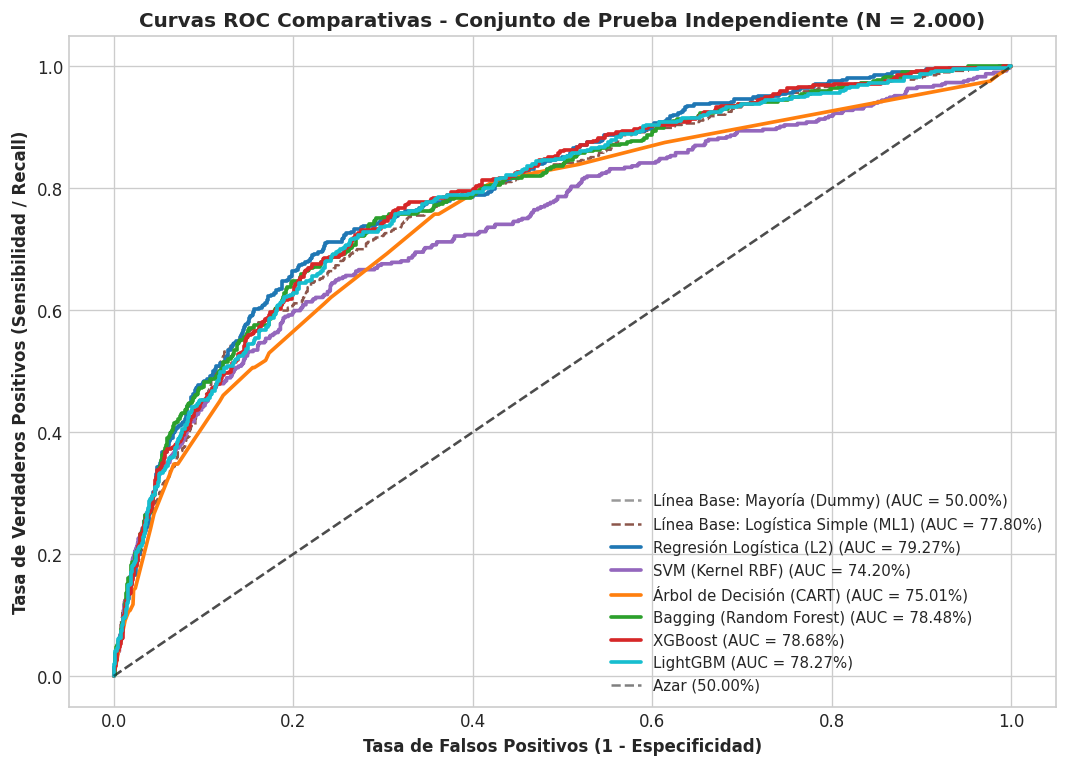

In [10]:
plt.figure(figsize=(9, 6.5))
palette = {
    'Línea Base: Mayoría (Dummy)': '#999999',
    'Línea Base: Logística Simple (ML1)': '#8c564b',
    'Regresión Logística (L2)': '#1f77b4',
    'SVM (Kernel RBF)': '#9467bd',
    'Árbol de Decisión (CART)': '#ff7f0e',
    'Bagging (Random Forest)': '#2ca02c',
    'XGBoost': '#d62728',
    'LightGBM': '#17becf'
}

for name, pipe in fitted_models.items():
    if hasattr(pipe, "predict_proba"):
        probs = pipe.predict_proba(X_test)[:, 1]
        auc_val = roc_auc_score(y_test, probs)
        fpr, tpr, _ = roc_curve(y_test, probs)
        ls = '--' if 'Línea Base' in name else '-'
        lw = 1.5 if 'Línea Base' in name else 2.2
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val*100:.2f}%)", color=palette.get(name, 'black'), linestyle=ls, linewidth=lw)
    else:
        plt.plot([0, 1], [0, 1], ':', label=f"{name} (AUC = 50.00%)", color='#999999')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Azar (50.00%)')
plt.title('Curvas ROC Comparativas - Conjunto de Prueba Independiente (N = 2.000)', fontsize=12, weight='bold')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', weight='bold')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)', weight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()


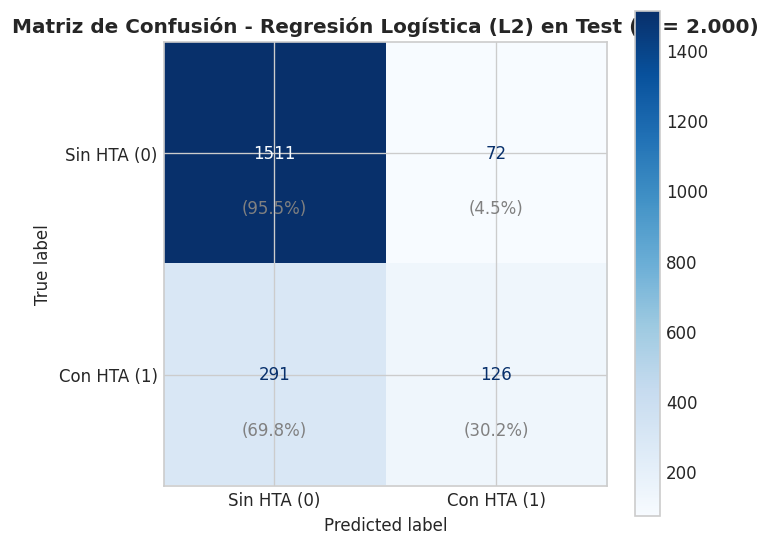

In [11]:
best_pipe = fitted_models['Regresión Logística (L2)']
y_pred = best_pipe.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
cm_norm = confusion_matrix(y_test, y_pred, normalize='true')

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sin HTA (0)', 'Con HTA (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
for i in range(2):
    for j in range(2):
        ax.text(j, i + 0.25, f"({cm_norm[i, j]*100:.1f}%)", ha="center", va="center", color="gray", fontsize=10)
ax.set_title('Matriz de Confusión - Regresión Logística (L2) en Test (N = 2.000)', weight='bold')
plt.tight_layout()
plt.show()


### 5.2 Explicabilidad e Importancia de Predictores
Contrastamos los coeficientes del modelo lineal ($L_2$) con la ganancia de información relativa en el ensamble no lineal XGBoost.


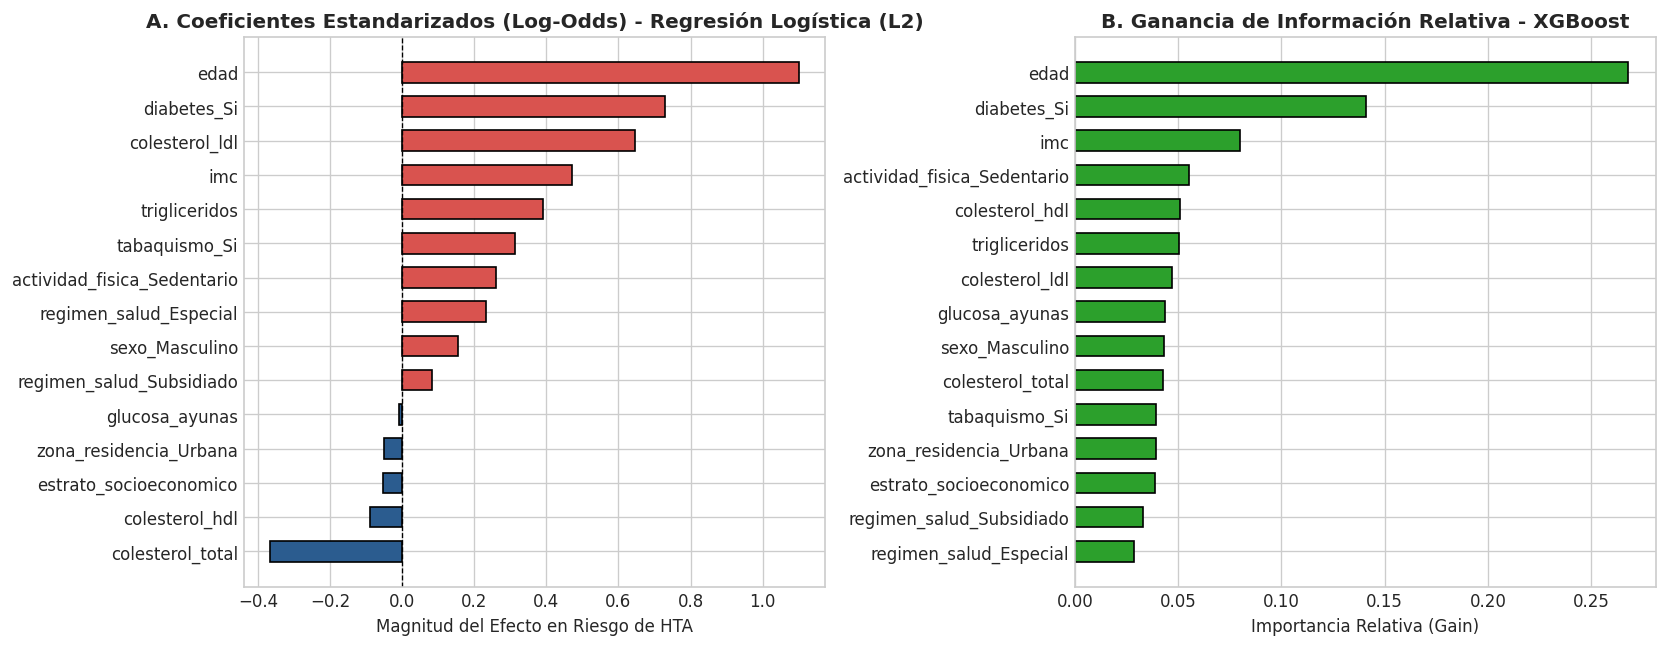

In [12]:
prep = best_pipe.named_steps['preprocessor']
cat_encoder = prep.named_transformers_['cat'].named_steps['encoder']
all_features = NUMERIC_FEATURES + cat_encoder.get_feature_names_out(CATEGORICAL_FEATURES).tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Coeficientes Logísticos
coefs = best_pipe.named_steps['classifier'].coef_[0]
df_coef = pd.DataFrame({'Variable': all_features, 'Coeficiente': coefs}).sort_values(by='Coeficiente', ascending=True)
colors = ['#d9534f' if c > 0 else '#2b5c8f' for c in df_coef['Coeficiente']]
axes[0].barh(df_coef['Variable'], df_coef['Coeficiente'], color=colors, edgecolor='black', height=0.6)
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title('A. Coeficientes Estandarizados (Log-Odds) - Regresión Logística (L2)', weight='bold')
axes[0].set_xlabel('Magnitud del Efecto en Riesgo de HTA')

# Importancia XGBoost
xgb_pipe = fitted_models['XGBoost']
imp = xgb_pipe.named_steps['classifier'].feature_importances_
df_imp = pd.DataFrame({'Variable': all_features, 'Importancia': imp}).sort_values(by='Importancia', ascending=True)
axes[1].barh(df_imp['Variable'], df_imp['Importancia'], color='#2ca02c', edgecolor='black', height=0.6)
axes[1].set_title('B. Ganancia de Información Relativa - XGBoost', weight='bold')
axes[1].set_xlabel('Importancia Relativa (Gain)')

plt.tight_layout()
plt.show()


## 6. Conclusiones y Proyección para la Entrega Final (Fase 3)
1. **Solidez Metodológica:** Se eliminó la inconsistencia de particiones de Miah et al. (2024), garantizando un pipeline 100% reproducible sin fuga de datos bajo validación cruzada estratificada de 10 pliegues.
2. **Desempeño:** La Regresión Logística ($L_2$) y XGBoost lograron la mayor capacidad discriminativa ($ROC\text{-}AUC pprox 78-79\%$), superando ampliamente a los clasificadores basales.
3. **Relevancia Clínica:** La edad, el índice de masa corporal, el diagnóstico de diabetes y el sedentarismo constituyen los ejes explicativos fundamentales del riesgo cardiovascular en Colombia, en concordancia directa con la Guía de Práctica Clínica No. 18 de MinSalud y la Cuenta de Alto Costo.
4. **Próximos Pasos (Fase 3):** Despliegue de una aplicación web interactiva en **Streamlit** y generación de explicaciones locales con **SHAP**.
